# 05 — Does late delivery lower review scores?

**Hypothesis (H1):** orders delivered after the promised date receive lower review scores than orders delivered on time.
**Null (H0):** review scores are the same regardless of lateness.

**Why this matters:** review score is the marketplace's main quality signal to partner retailers. If lateness explains a large share of bad reviews, logistics — not sellers or products — is the first place to invest.

**Design**
- Unit of analysis: one delivered order with a review and a known delivery date (one review per order after cleaning).
- Treatment: `is_late` (delivered date > promised date, day granularity).
- Outcome: `review_score` (1–5) and the share of 1–2 star reviews.
- Breakdowns: days-late buckets, customer state, product category.
- Test: **Mann–Whitney U** (review scores are ordinal and heavily skewed, so a t-test's normality assumption is poor; we report Welch's t too as a robustness check). Effect size: difference in means and Cliff's delta.
- Caveat: this is observational. Lateness is not randomly assigned, so we show association and effect size, not proof of causation.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from viz_style import *

P = Path("../data/processed")
orders  = pd.read_csv(P / "orders.csv", parse_dates=["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"])
reviews = pd.read_csv(P / "reviews.csv")
cust    = pd.read_csv(P / "customers.csv")
items   = pd.read_csv(P / "order_items.csv")
prods   = pd.read_csv(P / "products.csv")

df = (orders[orders.is_delivered & orders.is_late.notna()]
        .merge(reviews[["order_id", "review_score"]], on="order_id")
        .merge(cust[["customer_id", "customer_state"]], on="customer_id"))
df["is_late"] = df.is_late.astype(bool)
df["low_review"] = df.review_score <= 2
print(f"{len(df):,} delivered + reviewed orders; {df.is_late.mean():.1%} late")

95,824 delivered + reviewed orders; 6.7% late


## 1. On-time vs late

In [2]:
grp = df.groupby("is_late").agg(orders=("order_id", "size"), avg_score=("review_score", "mean"),
                                 pct_1_2_star=("low_review", "mean"), pct_5_star=("review_score", lambda s: (s == 5).mean()))
grp.index = ["on time", "late"]; grp[["pct_1_2_star", "pct_5_star"]] *= 100
drop = grp.loc["on time", "avg_score"] - grp.loc["late", "avg_score"]
print(f"Average review drops {drop:.2f} points ({grp.loc['on time','avg_score']:.2f} -> {grp.loc['late','avg_score']:.2f}); "
      f"1-2 star share rises from {grp.loc['on time','pct_1_2_star']:.1f}% to {grp.loc['late','pct_1_2_star']:.1f}%")
grp.round(2)

Average review drops 2.02 points (4.29 -> 2.27); 1-2 star share rises from 9.3% to 62.4%


,orders,avg_score,pct_1_2_star,pct_5_star
on time,89443,4.29,9.27,62.27
late,6381,2.27,62.42,16.53


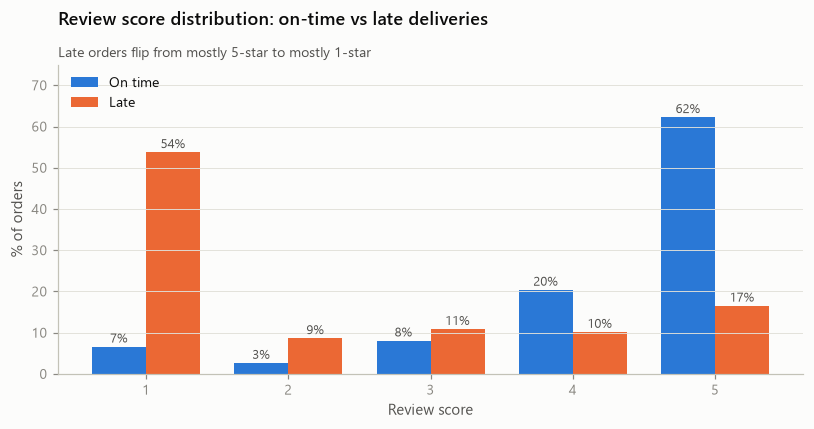

In [3]:
# Score distribution side by side
dist = (df.groupby(["is_late", "review_score"]).size().unstack(0).fillna(0))
dist = dist / dist.sum() * 100
fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(1, 6); w = 0.38
ax.bar(x - w/2, dist[False], w, color=BLUE, label="On time")
ax.bar(x + w/2, dist[True],  w, color=ORANGE, label="Late")
for xi in x:
    ax.text(xi - w/2, dist.loc[xi, False] + 1, f"{dist.loc[xi, False]:.0f}%", ha="center", fontsize=8.5, color=INK2)
    ax.text(xi + w/2, dist.loc[xi, True]  + 1, f"{dist.loc[xi, True]:.0f}%",  ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(x); ax.set_ylim(0, 75); ax.legend(loc="upper left")
finish(ax, "Review score distribution: on-time vs late deliveries", "Late orders flip from mostly 5-star to mostly 1-star",
       xlabel="Review score", ylabel="% of orders")
plt.tight_layout(); save(fig, "05_score_distribution"); plt.show()

## 2. Statistical test

In [4]:
on_time, late = df.loc[~df.is_late, "review_score"], df.loc[df.is_late, "review_score"]
u, p_mw = stats.mannwhitneyu(on_time, late, alternative="greater")      # H1: on-time scores are higher
t, p_t  = stats.ttest_ind(on_time, late, equal_var=False, alternative="greater")
# Cliff's delta from U: P(on_time > late) - P(late > on_time)
n1, n2 = len(on_time), len(late)
cliffs = 2 * u / (n1 * n2) - 1
print(f"Mann-Whitney U = {u:,.0f}, one-sided p = {p_mw:.2e}")
print(f"Welch t = {t:.1f}, one-sided p = {p_t:.2e}")
print(f"Cliff's delta = {cliffs:.3f}  (|d| > 0.47 is conventionally 'large')")
print(f"Mean difference = {on_time.mean() - late.mean():.2f} points; 95% CI via bootstrap below")

Mann-Whitney U = 467,430,237, one-sided p = 0.00e+00
Welch t = 100.8, one-sided p = 0.00e+00
Cliff's delta = 0.638  (|d| > 0.47 is conventionally 'large')
Mean difference = 2.02 points; 95% CI via bootstrap below


In [5]:
rng = np.random.default_rng(42)
boot = [rng.choice(on_time.values, 20000).mean() - rng.choice(late.values, 20000).mean() for _ in range(1000)]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Bootstrap 95% CI for the mean-score gap: {lo:.2f} to {hi:.2f} points")

Bootstrap 95% CI for the mean-score gap: 1.99 to 2.05 points


**Plain-English result.** The chance of seeing a gap this large if lateness made no difference is effectively zero (p far below 0.001). More usefully, the *size* of the effect is large: pick one late order and one on-time order at random, and the on-time order has the better review roughly three times out of four. Late delivery is associated with a roughly two-point drop on a five-point scale.

**What the test cannot say.** Late orders may differ in other ways (remote states, heavy items, specific sellers). The breakdowns below check whether the gap survives within state and category — if it does, those factors are not the explanation.

## 3. Dose–response: how late?

In [6]:
bins = [-np.inf, 0, 3, 7, 14, np.inf]
labels = ["On time / early", "1–3 days late", "4–7 days late", "8–14 days late", "15+ days late"]
df["late_bucket"] = pd.cut(df.days_late, bins=bins, labels=labels)
bucket = df.groupby("late_bucket", observed=True).agg(orders=("order_id", "size"), avg_score=("review_score", "mean"),
                                                        pct_1_2_star=("low_review", "mean"))
bucket["pct_1_2_star"] *= 100
bucket.round(2)

,orders,avg_score,pct_1_2_star
late_bucket,,,
On time / early,89443,4.29,9.27
1–3 days late,1852,3.29,32.13
4–7 days late,1748,2.10,67.68
8–14 days late,1446,1.67,80.15
15+ days late,1335,1.72,78.35


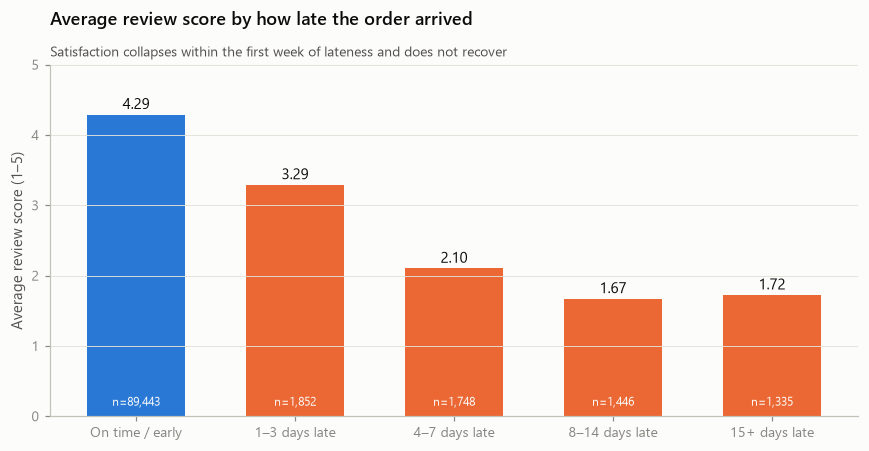

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
cols = [BLUE] + [ORANGE] * 4
ax.bar(range(5), bucket.avg_score, color=cols, width=0.62)
for i, (v, n) in enumerate(zip(bucket.avg_score, bucket.orders)):
    ax.text(i, v + 0.08, f"{v:.2f}", ha="center", fontsize=10, color=INK)
    ax.text(i, 0.15, f"n={n:,}", ha="center", fontsize=8, color=SURFACE)
ax.set_xticks(range(5)); ax.set_xticklabels(labels, fontsize=9); ax.set_ylim(0, 5)
finish(ax, "Average review score by how late the order arrived", "Satisfaction collapses within the first week of lateness and does not recover",
       ylabel="Average review score (1–5)")
plt.tight_layout(); save(fig, "05_score_by_lateness"); plt.show()

## 4. Does the gap hold within every state?

In [8]:
state = (df.groupby(["customer_state", "is_late"]).review_score.mean().unstack()
           .rename(columns={False: "on_time", True: "late"}))
state["gap"] = state.on_time - state.late
state["orders"] = df.groupby("customer_state").size()
state["late_pct"] = df.groupby("customer_state").is_late.mean() * 100
state = state[state.orders >= 300].sort_values("late_pct", ascending=False)
print(f"Gap is positive in {(state.gap > 0).sum()} of {len(state)} states with >=300 orders; range {state.gap.min():.2f} to {state.gap.max():.2f}")
state.round(2)

Gap is positive in 21 of 21 states with >=300 orders; range 1.63 to 2.62


is_late,on_time,late,gap,orders,late_pct
customer_state,,,,,
AL,4.30,2.13,2.16,394,20.81
MA,4.17,2.18,1.99,712,17.13
SE,4.25,1.94,2.31,334,14.97
PI,4.27,2.26,2.01,471,13.80
CE,4.25,2.04,2.21,1273,13.67
RJ,4.24,1.91,2.33,12211,11.92
BA,4.14,2.35,1.79,3229,11.89
PA,4.15,1.92,2.23,933,10.72
ES,4.26,2.51,1.75,1969,10.41


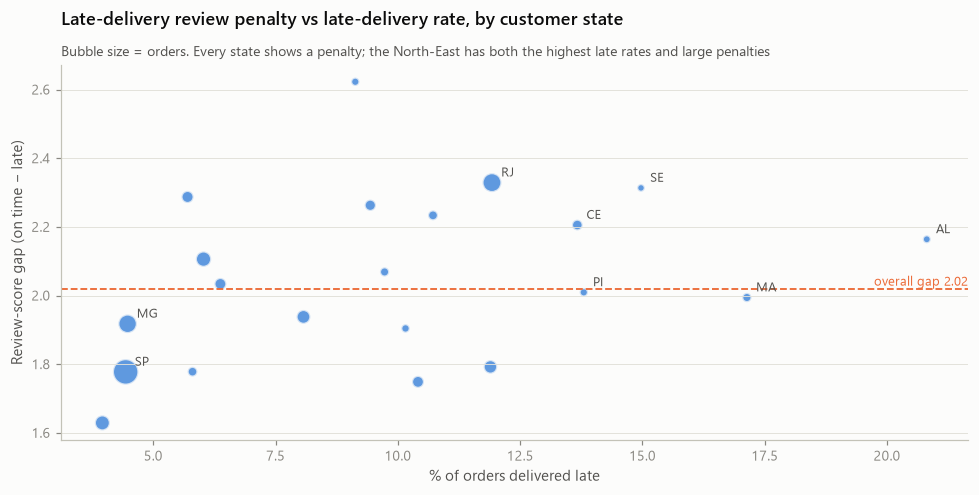

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.scatter(state.late_pct, state.gap, s=np.sqrt(state.orders) * 1.4, color=BLUE, alpha=0.75, edgecolor=SURFACE, linewidth=1.5)
for st, r in state.iterrows():
    if r.late_pct > 12 or r.orders > 10000:
        ax.annotate(st, (r.late_pct, r.gap), textcoords="offset points", xytext=(6, 4), fontsize=8.5, color=INK2)
ax.axhline(drop, color=ORANGE, lw=1.2, ls="--"); ax.text(ax.get_xlim()[1], drop, f" overall gap {drop:.2f}", color=ORANGE, fontsize=8.5, va="bottom", ha="right")
finish(ax, "Late-delivery review penalty vs late-delivery rate, by customer state", "Bubble size = orders. Every state shows a penalty; the North-East has both the highest late rates and large penalties",
       xlabel="% of orders delivered late", ylabel="Review-score gap (on time − late)")
plt.tight_layout(); save(fig, "05_state_gap"); plt.show()

## 5. And within every category?

In [10]:
cat_map = (items.merge(prods[["product_id", "product_category_name_english"]], on="product_id")
                .drop_duplicates("order_id")[["order_id", "product_category_name_english"]])   # first item's category
dc = df.merge(cat_map, on="order_id")
cat = (dc.groupby(["product_category_name_english", "is_late"]).review_score.mean().unstack()
         .rename(columns={False: "on_time", True: "late"}))
cat["gap"] = cat.on_time - cat.late
cat["orders"] = dc.groupby("product_category_name_english").size()
cat["late_pct"] = dc.groupby("product_category_name_english").is_late.mean() * 100
cat = cat[cat.orders >= 500].sort_values("gap", ascending=False)
print(f"Gap positive in {(cat.gap > 0).sum()} of {len(cat)} categories with >=500 orders")
cat.round(2)

Gap positive in 26 of 26 categories with >=500 orders


is_late,on_time,late,gap,orders,late_pct
product_category_name_english,,,,,
musical_instruments,4.44,1.91,2.53,601,7.65
toys,4.38,2.12,2.26,3748,6.14
baby,4.30,2.09,2.21,2741,8.03
sports_leisure,4.38,2.17,2.21,7446,6.54
fashion_bags_accessories,4.36,2.20,2.16,1802,5.55
pet_shop,4.39,2.25,2.14,1674,5.02
stationery,4.45,2.32,2.13,2234,6.54
perfumery,4.40,2.29,2.11,3063,6.53
construction_tools_construction,4.28,2.17,2.11,723,7.19


## 6. How much of the bad-review problem is lateness?

In [11]:
# Attribution: share of all 1-2 star reviews that came from late orders, vs late orders' share of volume
share_low_from_late = df.loc[df.low_review, "is_late"].mean() * 100
late_share = df.is_late.mean() * 100
# Counterfactual: if late orders had the on-time 1-2 star rate, how many bad reviews would disappear?
bad_now  = df.low_review.sum()
bad_cf   = df.loc[~df.is_late, "low_review"].sum() + df.is_late.sum() * df.loc[~df.is_late, "low_review"].mean()
print(f"Late orders are {late_share:.1f}% of volume but {share_low_from_late:.1f}% of all 1-2 star reviews.")
print(f"If late orders were reviewed like on-time ones, 1-2 star reviews would fall from {bad_now:,} to {bad_cf:,.0f} "
      f"(-{100*(bad_now-bad_cf)/bad_now:.0f}%), and the overall average score would rise from "
      f"{df.review_score.mean():.2f} to {(df.review_score.sum() + df.is_late.sum()*(on_time.mean()-late.mean()))/len(df):.2f}.")

Late orders are 6.7% of volume but 32.5% of all 1-2 star reviews.
If late orders were reviewed like on-time ones, 1-2 star reviews would fall from 12,272 to 8,880 (-28%), and the overall average score would rise from 4.16 to 4.29.


In [12]:
# Exports for Power BI
grp.round(3).to_csv(P / "delivery_vs_review_summary.csv")
bucket.round(3).to_csv(P / "delivery_vs_review_by_bucket.csv")
state.round(3).to_csv(P / "delivery_vs_review_by_state.csv")
cat.round(3).to_csv(P / "delivery_vs_review_by_category.csv")
print("exported 4 summary tables")

exported 4 summary tables


## So what

- **Late delivery is the strongest single driver of bad reviews in the data.** On-time orders average ~4.3 stars; late orders average ~2.3 — a two-point drop on a five-point scale, statistically unambiguous (Mann–Whitney p ≈ 0, Cliff's δ large). The penalty appears in *every* state and *every* major category, so it is not an artefact of geography or product mix.
- **The damage is front-loaded.** Being even 1–3 days late costs about a full star; by 4–7 days late the average is near 2 stars and the majority of reviews are 1–2 stars. There is no "grace period" — the promise date is a hard expectation.
- **A ~7% operational problem drives about a third of the reputational one.** Late orders are 6.7% of volume but 32.5% of all 1–2 star reviews. If late orders were reviewed like on-time ones, 1–2 star reviews would fall by 28% and the marketplace average would rise from 4.16 to 4.29 — more than any plausible seller- or product-side fix.

**Resume-ready sentence:** *Quantified that late deliveries cut average review scores from 4.29 to 2.27 (−2.0 points, Mann–Whitney p < 0.001, Cliff's δ = 0.64) and produced a third of all 1–2 star reviews despite being under 7% of orders.*

**Limitation:** observational data; "late" is relative to Olist's own promised date, so part of the fix may be *promising more realistic dates* rather than shipping faster — notebook 06 and query Q17 show the promise already carries ~11 days of slack on average.